In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Generate non-linear data (y = x^2 + 2 with slight noise)
np.random.seed(42)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([3, 6, 11, 18, 27, 38, 51, 66, 83, 102]) # Exact quadratic curve + noise if desired

In [2]:
# 1. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Set degree for Polynomial Regression
degree = 2
poly = PolynomialFeatures(degree=degree)

# 3. Transform features (Fit transformation on train data only to prevent data leakage)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Transformed X_train_poly shape:", X_train_poly.shape)

Original X_train shape: (8, 1)
Transformed X_train_poly shape: (8, 3)


In [3]:
# Train Linear Regression on transformed polynomial features
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Predictions
y_train_pred = model.predict(X_train_poly)
y_test_pred = model.predict(X_test_poly)

# Evaluation Metrics
print(f"Intercept (b0): {model.intercept_:.4f}")
print(f"Coefficients (b1, b2...): {model.coef_}")

print("\n--- Performance Metrics ---")
print(f"Train MSE: {mean_squared_error(y_train, y_train_pred):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_test_pred):.4f}")
print(f"Train R²:  {r2_score(y_train, y_train_pred):.4f}")
print(f"Test R²:   {r2_score(y_test, y_test_pred):.4f}")

Intercept (b0): 2.0000
Coefficients (b1, b2...): [0.0000000e+00 4.4408921e-16 1.0000000e+00]

--- Performance Metrics ---
Train MSE: 0.0000
Test MSE:  0.0000
Train R²:  1.0000
Test R²:   1.0000


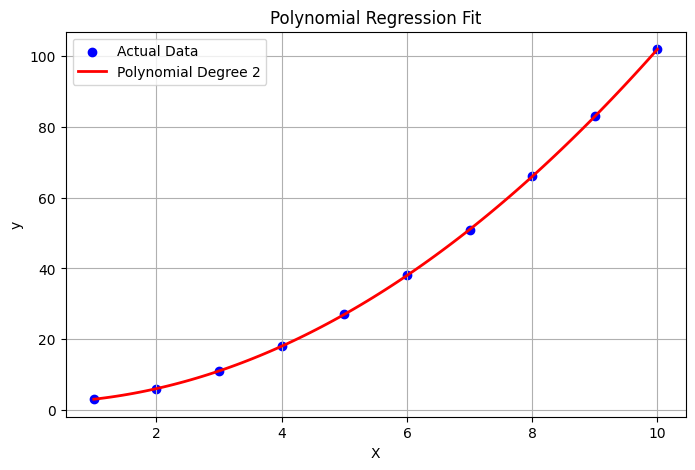

In [4]:
# Generate continuous X values for a smooth curve
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_range_poly = poly.transform(X_range)
y_range_pred = model.predict(X_range_poly)

# Plotting
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label=f'Polynomial Degree {degree}')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Polynomial Regression Fit')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
from sklearn.model_selection import cross_val_score

for d in range(1, 6):
    poly_degree = PolynomialFeatures(degree=d)
    X_poly_all = poly_degree.fit_transform(X)
    
    regressor = LinearRegression()
    # 5-fold cross validation using negative mean squared error
    mse_scores = -cross_val_score(
        regressor, X_poly_all, y, cv=5, scoring='neg_mean_squared_error'
    )
    
    print(f"Degree {d} | Mean CV MSE: {mse_scores.mean():.4f}")

Degree 1 | Mean CV MSE: 204.0625
Degree 2 | Mean CV MSE: 0.0000
Degree 3 | Mean CV MSE: 0.0000
Degree 4 | Mean CV MSE: 0.0000
Degree 5 | Mean CV MSE: 0.0000
